In [1]:
import torch

In [86]:
import seaborn as sbn
from numpy import random
import math
import pandas as pd
import matplotlib.pyplot as plt
from torch.nn.functional import one_hot as oneHot
from torch.nn.functional import cross_entropy
from torch.nn.functional import softmax

In [3]:
with open('./bigramsData/names.txt','r') as f:
    words=[i.strip() for i in f.readlines()]

In [ ]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i for i,s in enumerate(chars,1)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26]

In [14]:
[1,2,3][1:]+[ix]

[2, 3, 0]

In [10]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words:
  
  #print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
... ---> a
..a ---> v
.av ---> a
ava ---> .
... ---> i
..i ---> s
.is ---> a
isa ---> b
sab ---> e
abe ---> l
bel ---> l
ell ---> a
lla ---> .
... ---> s
..s ---> o
.so ---> p
sop ---> h
oph ---> i
phi ---> a
hia ---> .
... ---> c
..c ---> h
.ch ---> a
cha ---> r
har ---> l
arl ---> o
rlo ---> t
lot ---> t
ott ---> e
tte ---> .
... ---> m
..m ---> i
.mi ---> a
mia ---> .
... ---> a
..a ---> m
.am ---> e
ame ---> l
mel ---> i
eli ---> a
lia ---> .
... ---> h
..h ---> a
.ha ---> r
har ---> p
arp ---> e
rpe ---> r
per ---> .
... ---> e
..e ---> v
.ev ---> e
eve ---> l
vel ---> y
ely ---> n
lyn ---> .
... ---> a
..a ---> b
.ab ---> i
abi ---> g
big ---> a
iga ---> i
gai ---> l
ail ---> .
... ---> e
..e ---> m
.em ---> i
emi ---> l
mil ---> y
ily ---> .
... ---> e
..e ---> l
.el ---> i
eli ---> z
liz ---> a
iza ---> b
zab ---> e
abe ---> t
bet ---> h
eth ---> .

In [12]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [58]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    # print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      # print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182424, 3]) torch.Size([182424])
torch.Size([22836, 3]) torch.Size([22836])
torch.Size([22886, 3]) torch.Size([22886])


* C is lookup table, where 27 character are expressed in 10 dimensions
*  so if orignal vector space is 32,3 i.e each character is repersented in 3 dim, when we do C[x] we get 32,3,10 where we have the 32,3 vector space expersied in 10 dim

In [66]:
X[13,2]

tensor(1)

In [67]:
C=torch.randn((27,2))
C[X][13,2]

tensor([0.3495, 0.9161])

In [68]:
C[1]

tensor([0.3495, 0.9161])

So the character which is situated in X vector at 13,2 is 1, that 1 is now repersented in C as C[1], or C[X][13,2] gives us that characters embending

Here C is lookup table, where character are experesed as 2 dimensions in example character whose ID is 10 is expressed in 2 dimension

In [152]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn((1,200), generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn((1,27), generator=g)
parameters = [C, W1, b1, W2, b2]

In [153]:
for i in parameters:
    print(i.shape)

torch.Size([27, 10])
torch.Size([30, 200])
torch.Size([1, 200])
torch.Size([200, 27])
torch.Size([1, 27])


In [154]:
for p in parameters:
  p.requires_grad = True

In [143]:
Xtr.shape

torch.Size([182424, 3])

emb is 32,3,10 vector and W1 is 30,200 matrix, how do we make emb to 32,30 so that emb @ W1 can be run ?

In [155]:
stepi=[]
lossi=[]
for i in range(200000):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,)) # 32 random vectors from Xtr
  
  # forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)
  logits = h @ W2 + b2 # (32, 27)
  loss = cross_entropy(logits, Ytr[ix])
  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

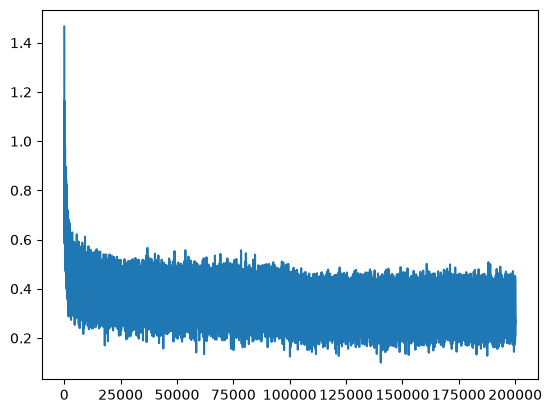

In [156]:
plt.plot(stepi, lossi)

In [157]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = cross_entropy(logits, Ytr)
loss

tensor(2.1237, grad_fn=<NllLossBackward0>)

In [158]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = cross_entropy(logits, Ydev)
loss

tensor(2.1718, grad_fn=<NllLossBackward0>)

In [159]:
emb = C[Xte] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = cross_entropy(logits, Yte)
loss

tensor(2.1713, grad_fn=<NllLossBackward0>)

In [171]:
import pandas as pd
cDF=pd.DataFrame(C.detach().numpy(),index=[itos[i] for i in sorted(itos.keys())],columns=[f'Dim_{i}' for i in range(10)])

In [183]:
help(PCA)

Help on class PCA in module sklearn.decomposition._pca:

class PCA(sklearn.decomposition._base._BasePCA)
 |  PCA(n_components=None, *, copy=True, whiten=False, svd_solver='auto', tol=0.0, iterated_power='auto', n_oversamples=10, power_iteration_normalizer='auto', random_state=None)
 |
 |  Principal component analysis (PCA).
 |
 |  Linear dimensionality reduction using Singular Value Decomposition of the
 |  data to project it to a lower dimensional space. The input data is centered
 |  but not scaled for each feature before applying the SVD.
 |
 |  It uses the LAPACK implementation of the full SVD or a randomized truncated
 |  SVD by the method of Halko et al. 2009, depending on the shape of the input
 |  data and the number of components to extract.
 |
 |  With sparse inputs, the ARPACK implementation of the truncated SVD can be
 |  used (i.e. through :func:`scipy.sparse.linalg.svds`). Alternatively, one
 |  may consider :class:`TruncatedSVD` where the data are not centered.
 |
 |  No

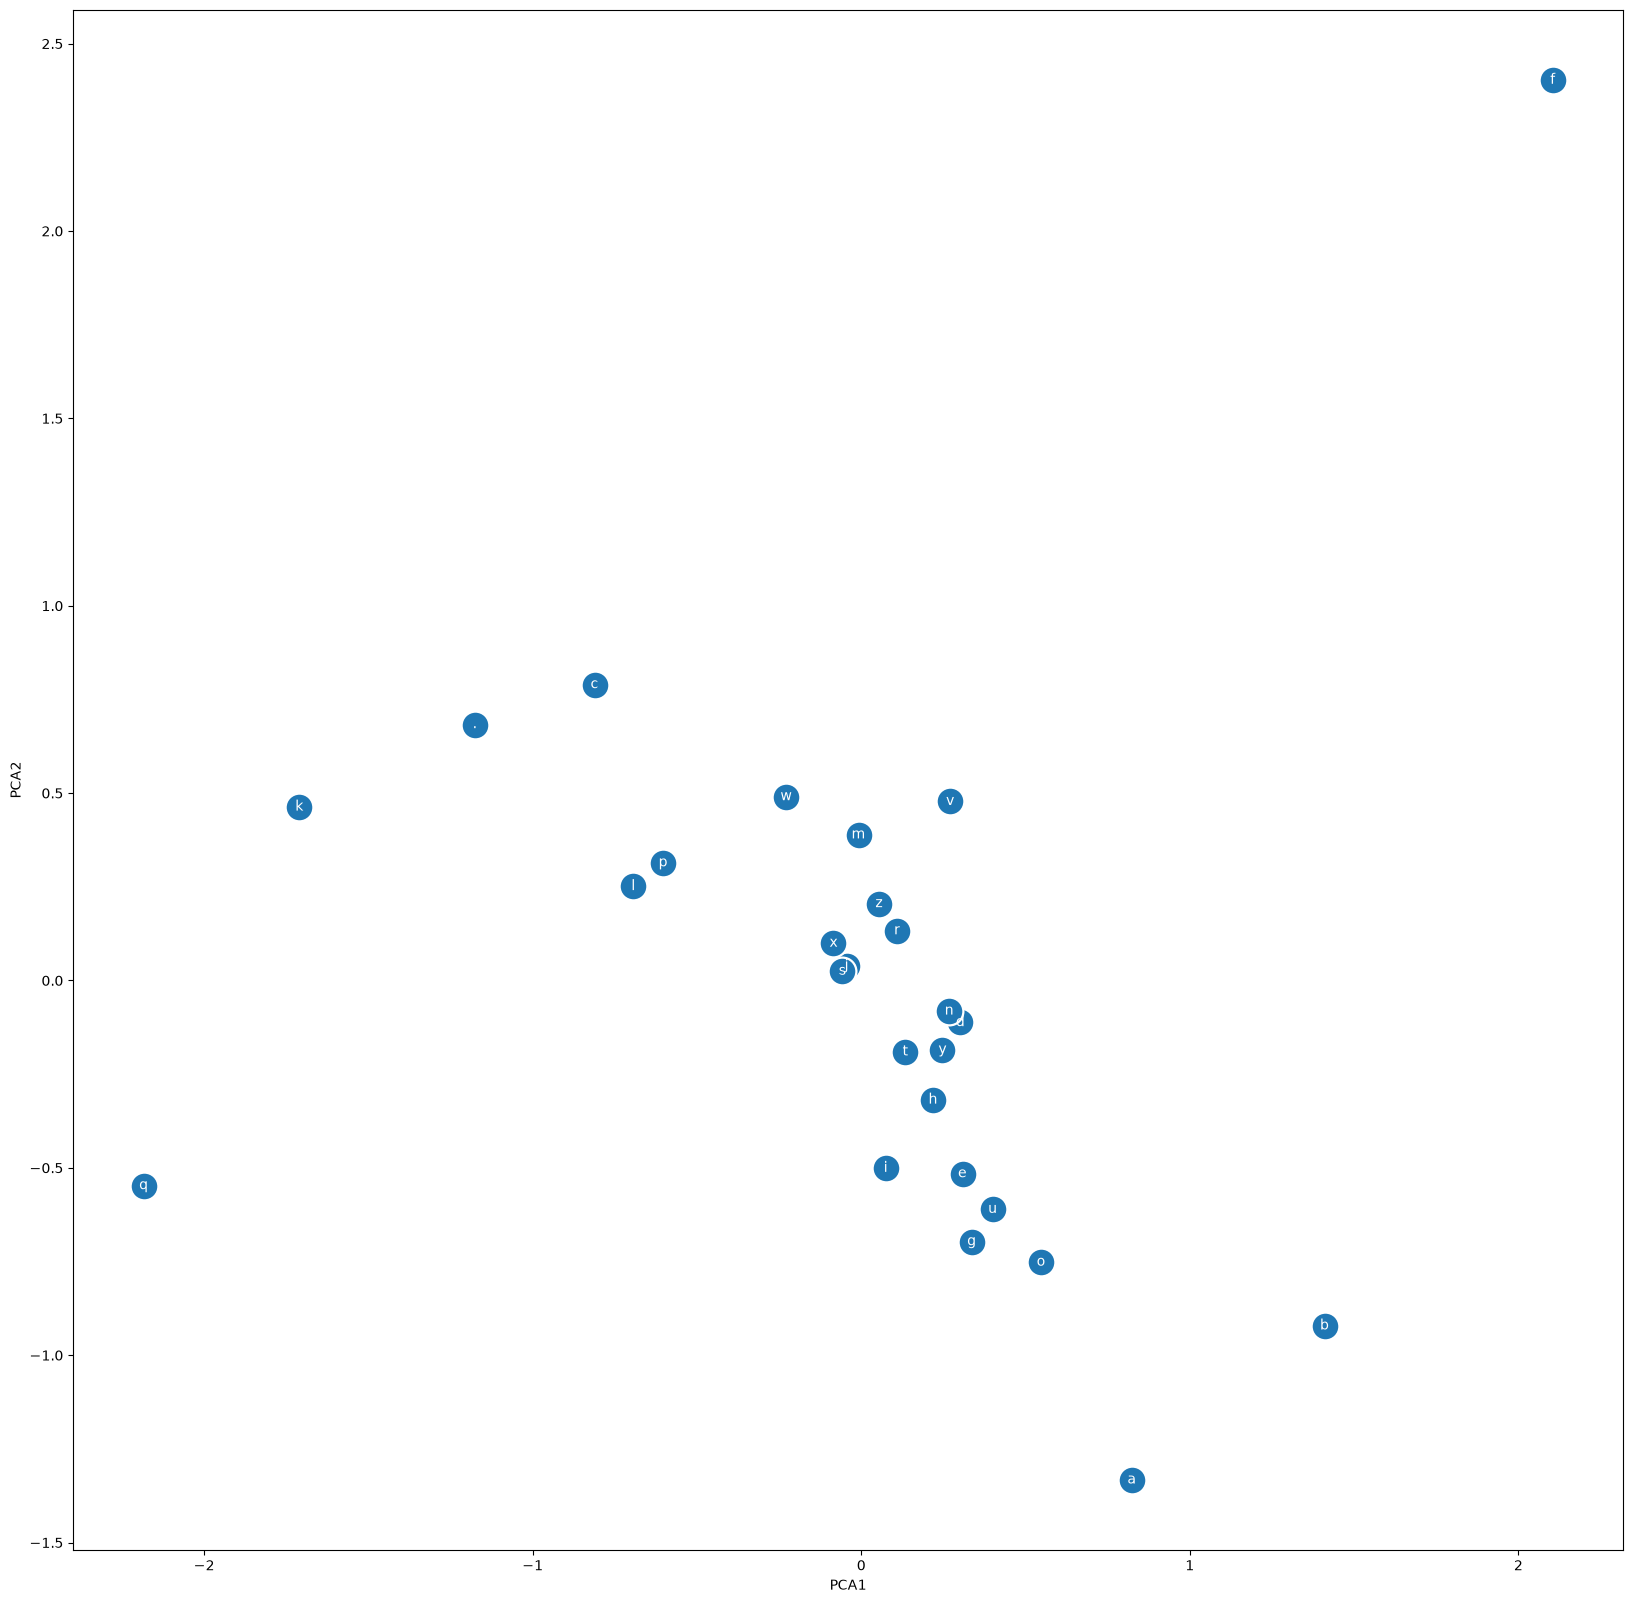

In [214]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca=PCA(n_components=2)
pcaDF=pd.DataFrame(pca.fit_transform(cDF.values),index=cDF.index,columns=['PCA1','PCA2'])

fig,ax=plt.subplots(figsize=(20,20))
g=sbn.scatterplot(pcaDF,x='PCA1',y='PCA2',s=400)
for row in pcaDF.itertuples():
    x,y=row.PCA1,row.PCA2
    text=row.Index
    g.text(x,y,text,ha="center", va="center", color='white')

In [212]:
pca.explained_variance_

array([0.7228401 , 0.49960363], dtype=float32)

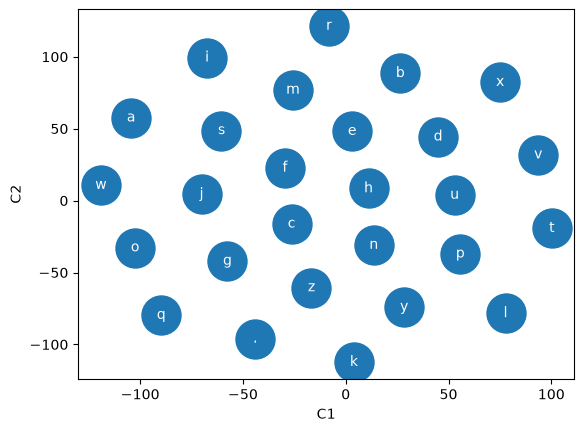

In [216]:
tsne=TSNE(n_components=2,perplexity =26)
tsneDF=pd.DataFrame(tsne.fit_transform(cDF.values),index=cDF.index,columns=['C1','C2'])

g=sbn.scatterplot(tsneDF,x='C1',y='C2',s=1000)
for row in tsneDF.itertuples():
    x,y=row.C1,row.C2
    text=row.Index
    g.text(x,y,text,ha="center", va="center", color='white')

In [222]:
from sklearn.manifold import trustworthiness

# Evaluate the top K nearest neighbors
score = trustworthiness(cDF.values, tsne.fit_transform(cDF.values), n_neighbors=3)
print(f"Trustworthiness Score: {score:.4f}")

Trustworthiness Score: 0.5123


In [220]:
tsne.kl_divergence_

0.4770985245704651

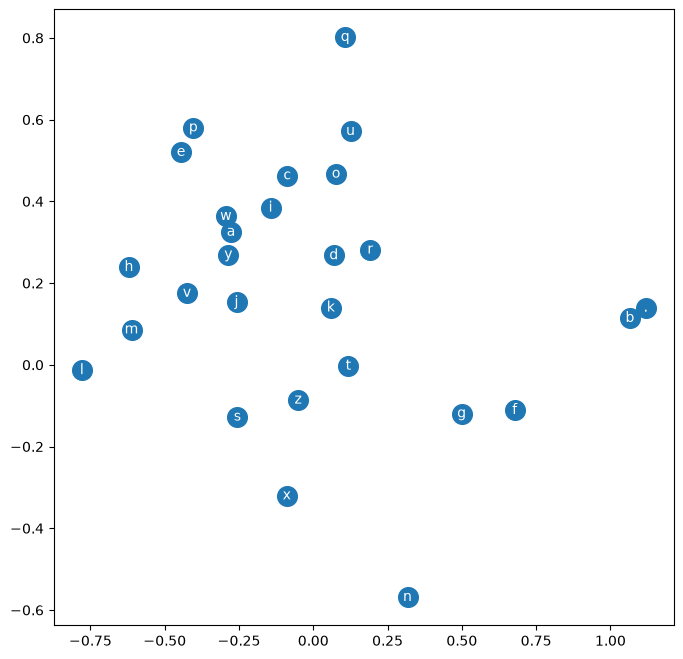

In [160]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
# plt.grid('minor')

In [161]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carmah.
amelle.
khi.
mili.
thold.
kanden.
jazonte.
deliah.
jarqui.
ner.
kiah.
maiir.
kaleigh.
ham.
jois.
quinn.
suline.
liveni.
wazelo.
dearyn.


In [125]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn((1,200), generator=g)
W2 = torch.randn((200, 100), generator=g)
b2 = torch.randn((1,100), generator=g)
W3 = torch.randn((100, 27), generator=g)
b3 = torch.randn((1,27), generator=g)
parameters = [C, W1, b1, W2, b2, W3,b3]
for i in parameters:
    print(i.shape)
    i.requires_grad=True

torch.Size([27, 10])
torch.Size([30, 200])
torch.Size([1, 200])
torch.Size([200, 100])
torch.Size([1, 100])
torch.Size([100, 27])
torch.Size([1, 27])


In [133]:
stepi=[]
lossi=[]
for i in range(200000):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,)) # 32 random vectors from Xtr
  
  # forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  L1 = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)=(32,30) @ (30,200)
  L2=torch.tanh(L1 @ W2 +b2) # (32,100) = (32,200) @ (200,100)
  L3=L2 @ W3 +b3 # (32,27) = (32,100) @ (100,27)

  loss = cross_entropy(L3, Ytr[ix])
  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

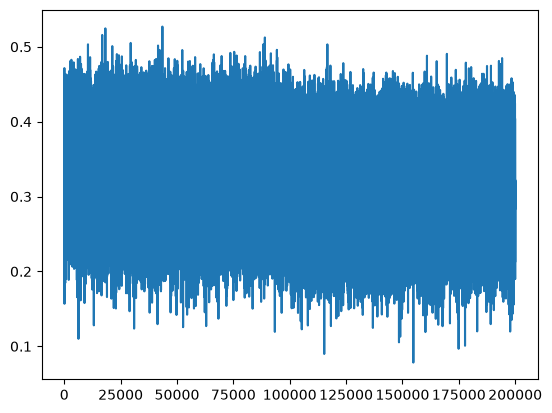

In [134]:
plt.plot(stepi, lossi)

In [135]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = cross_entropy(logits, Ytr)
loss

tensor(46.4327, grad_fn=<NllLossBackward0>)

In [136]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = cross_entropy(logits, Ydev)
loss

tensor(46.2983, grad_fn=<NllLossBackward0>)

In [137]:
emb = C[Xte] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = cross_entropy(logits, Yte)
loss

tensor(46.3131, grad_fn=<NllLossBackward0>)

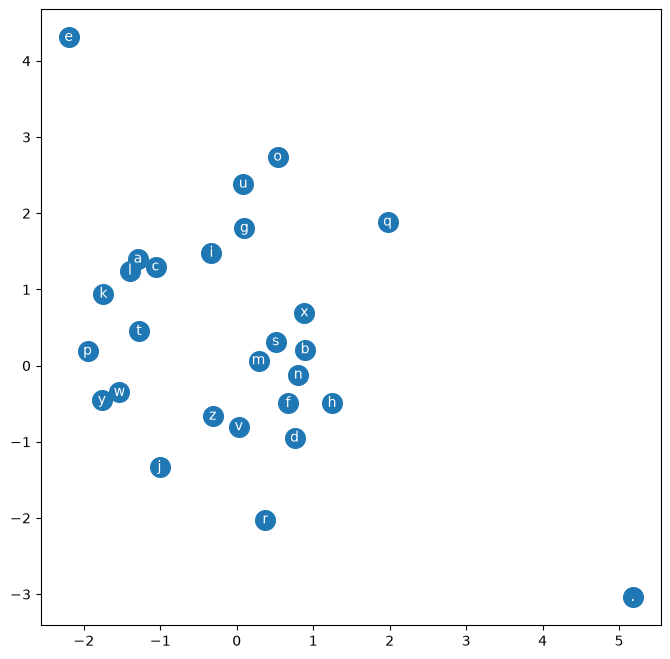

In [138]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
# plt.grid('minor')

In [139]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      L1 = torch.tanh(emb.view(1, -1) @ W1 + b1) # (32, 200)=(32,30) @ (30,200)
      L2=torch.tanh(L1 @ W2 +b2) # (32,100) = (32,200) @ (200,100)
      L3=L2 @ W3 +b3 # (32,27) = (32,100) @ (100,27)
      probs = softmax(L3, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carmah.
amillivi.
kimle.
reigh.
salayson.
mahnen.
den.
art.
kaeli.
nellara.
chaiivin.
leigh.
ham.
joce.
quint.
sulie.
alianni.
wazell.
dearynix.
kael.
